# 2. Data preprocessing and exploration

**Rubric section:** Data Preprocessing and Exploration (15 pts).

This notebook covers:
1. Building our own features from the text itself.
2. Removing redundant features.
3. Finding near-duplicate texts and template families.
4. Creating a train/test split that can't leak.

The heavy steps are scripts. Run them once, in order, from the repository root
(they take a few minutes):

```bash
python src/build_candidate_features.py   # full candidate feature set (several minutes)
python src/prepare_final_data.py         # reduced 7-feature CSV
python src/build_splits.py               # near-duplicate groups + split (about 2 minutes)
```

This notebook reads what those scripts wrote and explains each decision.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

# Works whether Jupyter starts in the repo root or in notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

FIGURES = ROOT / "reports" / "figures"
METRICS = ROOT / "reports" / "metrics"
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)


def show(name: str, width: int = 800) -> None:
    """Display a saved figure from reports/figures."""
    display(Image(filename=str(FIGURES / name), width=width))

## Step 1: Features come from the text only

**Rule (owner-approved):** every model input must be computable from the submitted text alone.
`src/text_features.py` computes each feature with a documented formula
(see `rubric_explanation/feature_derivation_spec.md`). Here it is on one sentence:

In [2]:
from text_features import extract_text_features
from prepare_final_data import FINAL_FEATURE_COLUMNS

example = "The quick brown fox jumps over the lazy dog. It was not amused, frankly!"
pd.Series({k: v for k, v in extract_text_features(example).items() if k in FINAL_FEATURE_COLUMNS})

/Users/lucascoelho/Desktop/fall-2026/csce-478/project/human-vs-ai-ml-project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Text_Word_Count                       14.000000
Text_Guiraud_Root_TTR                  3.474396
Text_Average_Word_Length               4.000000
Text_Average_Sentence_Length_Words     7.000000
Text_Punctuation_Density               0.041667
Text_Flesch_Kincaid_Grade_Level        3.154286
Text_Burstiness                       -0.555556
dtype: float64

## Step 2: Keep one feature from each signal family

The full candidate set has many redundant features (for example, raw counts that rise
together with text length). We keep one representative per family:

| Kept feature | Signal family |
| --- | --- |
| `Text_Word_Count` | length |
| `Text_Average_Word_Length` | word complexity |
| `Text_Average_Sentence_Length_Words` | sentence complexity |
| `Text_Guiraud_Root_TTR` | vocabulary variety |
| `Text_Punctuation_Density` | punctuation style |
| `Text_Flesch_Kincaid_Grade_Level` | readability (already includes syllables) |
| `Text_Burstiness` | variation in sentence length |

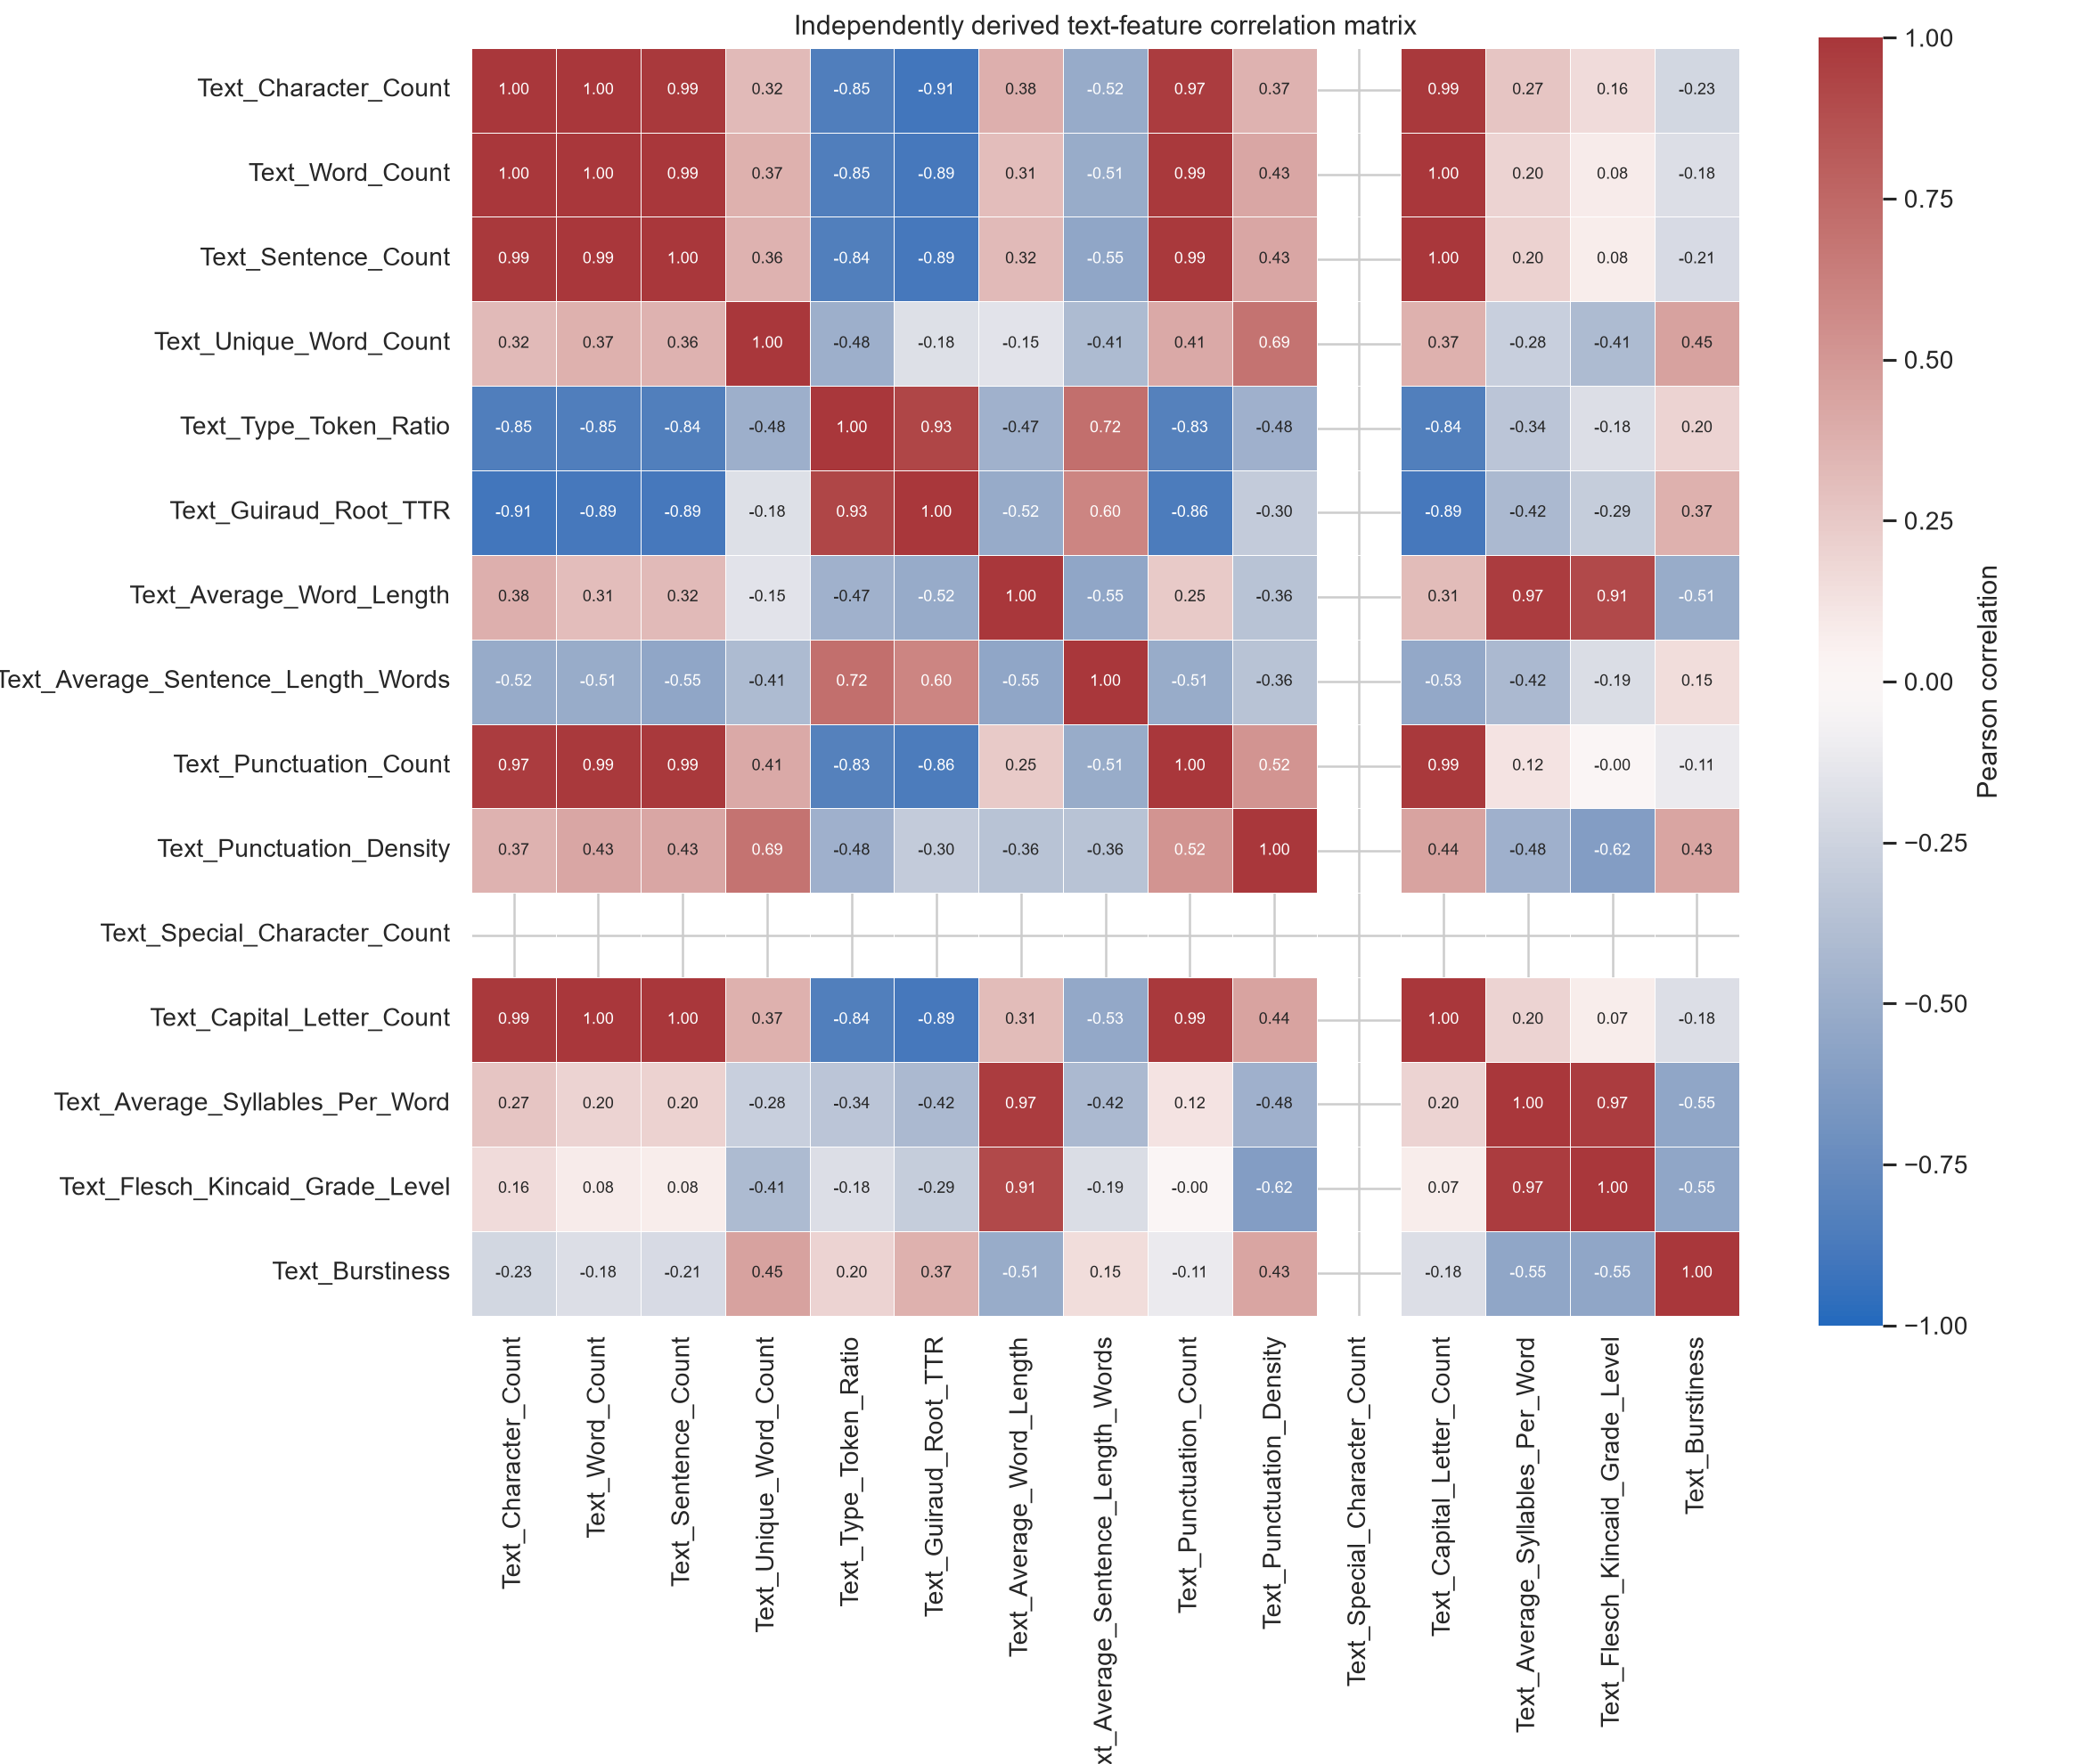

In [3]:
show("candidate_text_feature_correlation_matrix.png", 750)

In [4]:
from modeling import PROCESSED_PATH

processed = pd.read_csv(PROCESSED_PATH)
print(f"Processed rows: {len(processed):,}; columns: {list(processed.columns)}")
print("Missing values in model features:", int(processed[FINAL_FEATURE_COLUMNS].isna().sum().sum()))
processed.groupby("Label_Name")[FINAL_FEATURE_COLUMNS].median().T.round(3)

Processed rows: 50,000; columns: ['Text_ID', 'Raw_Text', 'Label', 'Label_Name', 'Text_Word_Count', 'Text_Average_Word_Length', 'Text_Average_Sentence_Length_Words', 'Text_Guiraud_Root_TTR', 'Text_Punctuation_Density', 'Text_Flesch_Kincaid_Grade_Level', 'Text_Burstiness']
Missing values in model features: 0


Label_Name,AI,Human
Text_Word_Count,246.000,251.000
Text_Average_Word_Length,6.988,6.152
Text_Average_Sentence_Length_Words,8.528,8.609
Text_Guiraud_Root_TTR,4.732,5.323
Text_Punctuation_Density,0.028,0.036
Text_Flesch_Kincaid_Grade_Level,15.800,11.317
Text_Burstiness,-0.515,-0.341


**Missing values:** none in the seven features. **Encoding:** no categorical inputs remain,
so nothing needs encoding. **Scaling:** done inside each model's pipeline and fit on
training folds only (logistic regression needs it; random forest does not).
**Outliers:** kept. These are real texts, and dropping extreme rows would change what the
model is tested on.

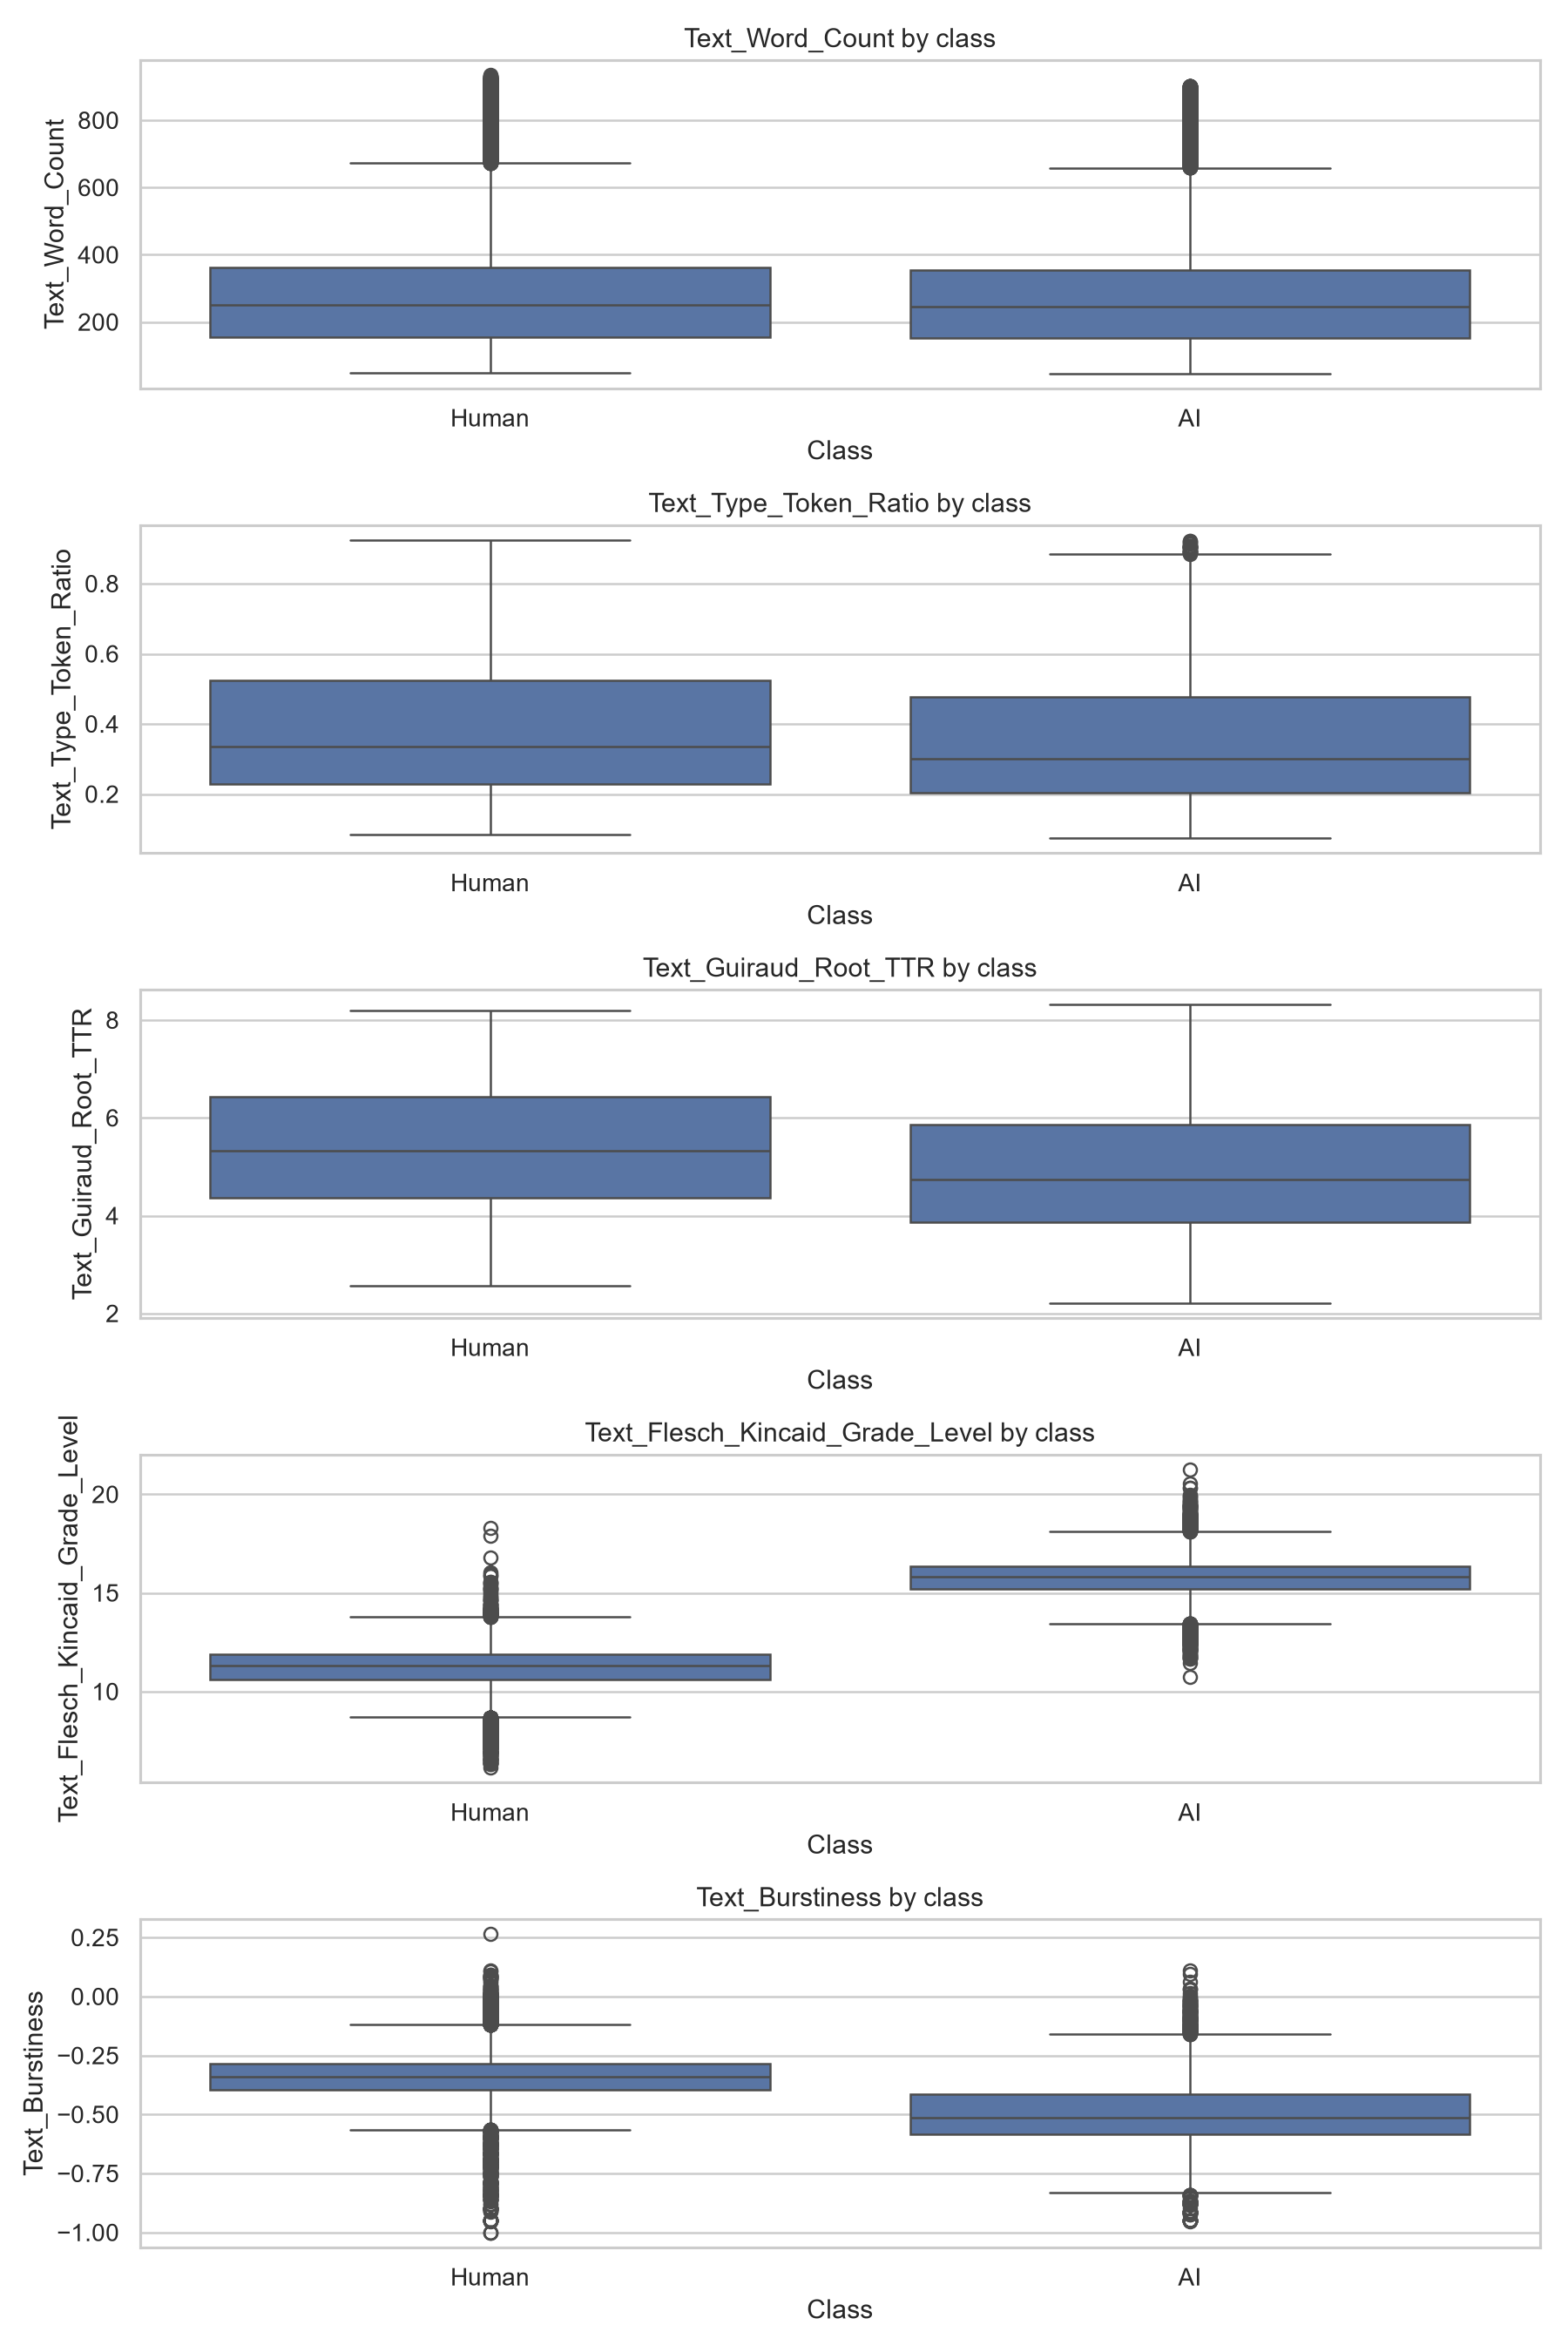

In [5]:
show("candidate_text_feature_distributions.png", 900)

## Step 3: Near-duplicates and template families

If almost the same text appeared in both training and test sets, the test score would be
too optimistic. `src/build_splits.py` compares every pair of texts by shared word
trigrams (three-word sequences) and groups:
- **near-duplicates** with similarity ≥ 0.82. These groups never cross the train/test split.
- **template families** with similarity ≥ 0.60. These are used for a harder stress test.

Both thresholds were chosen from the data. The histogram below shows how they were picked.

In [6]:
summary = json.loads((METRICS / "split_summary.json").read_text())
pd.Series({
    "rows": summary["rows"],
    "near-duplicate threshold": summary["near_dup_threshold"],
    "near-duplicate groups": summary["near_dup_groups"],
    "rows in multi-text groups": summary["near_dup_rows_in_multi_text_groups"],
    "largest group": summary["near_dup_largest_group"],
    "groups mixing Human and AI": summary["near_dup_mixed_label_groups"],
    "template families": summary["template_families"],
    "families mixing Human and AI": summary["mixed_label_families"],
    "max Human-AI pair similarity": summary["max_human_ai_pair_similarity"],
}).to_frame("value")

,value
rows,50000.00
near-duplicate threshold,0.82
near-duplicate groups,47779.00
rows in multi-text groups,3027.00
largest group,140.00
groups mixing Human and AI,0.00
template families,11.00
families mixing Human and AI,0.00
max Human-AI pair similarity,0.06


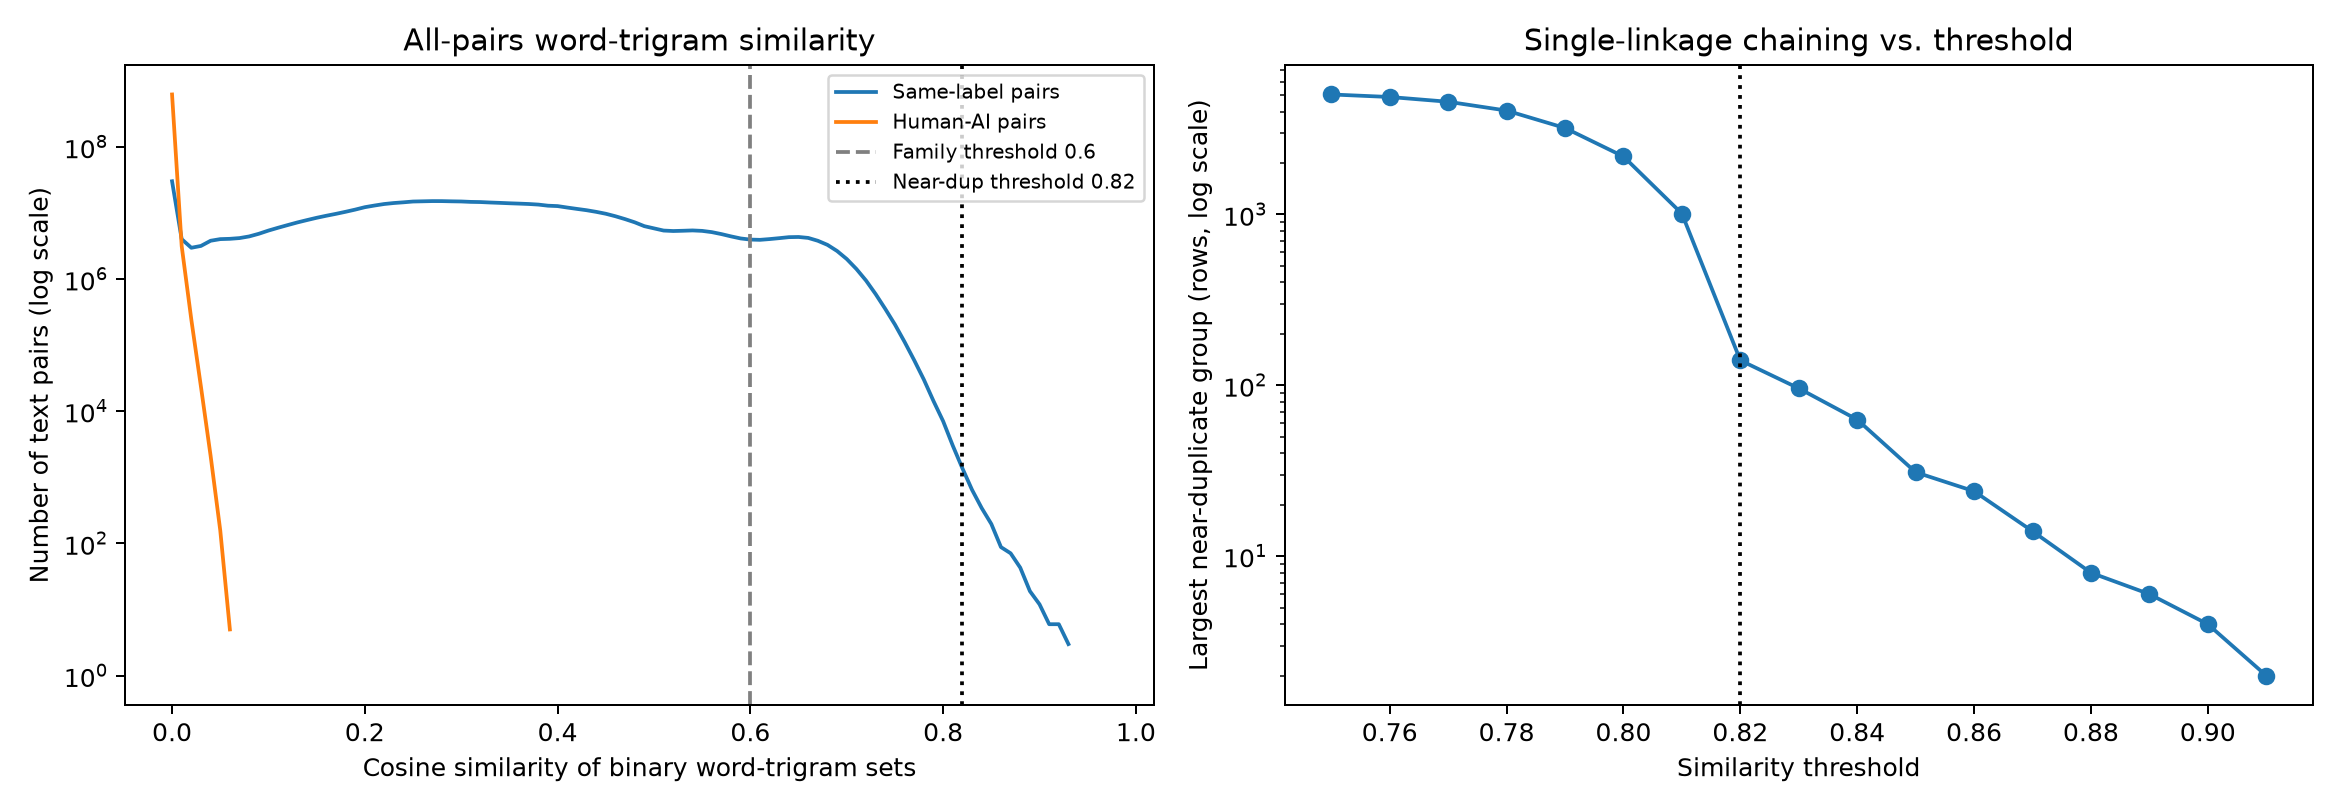

In [7]:
show("near_duplicate_similarity_diagnostics.png", 900)

**Key finding:** the 50,000 texts come from just **11 writing templates** (6 Human, 5 AI).
Every template belongs to one class. A model can score very high by recognizing the
template rather than human vs. AI writing in general. This is the main limitation of
the dataset.

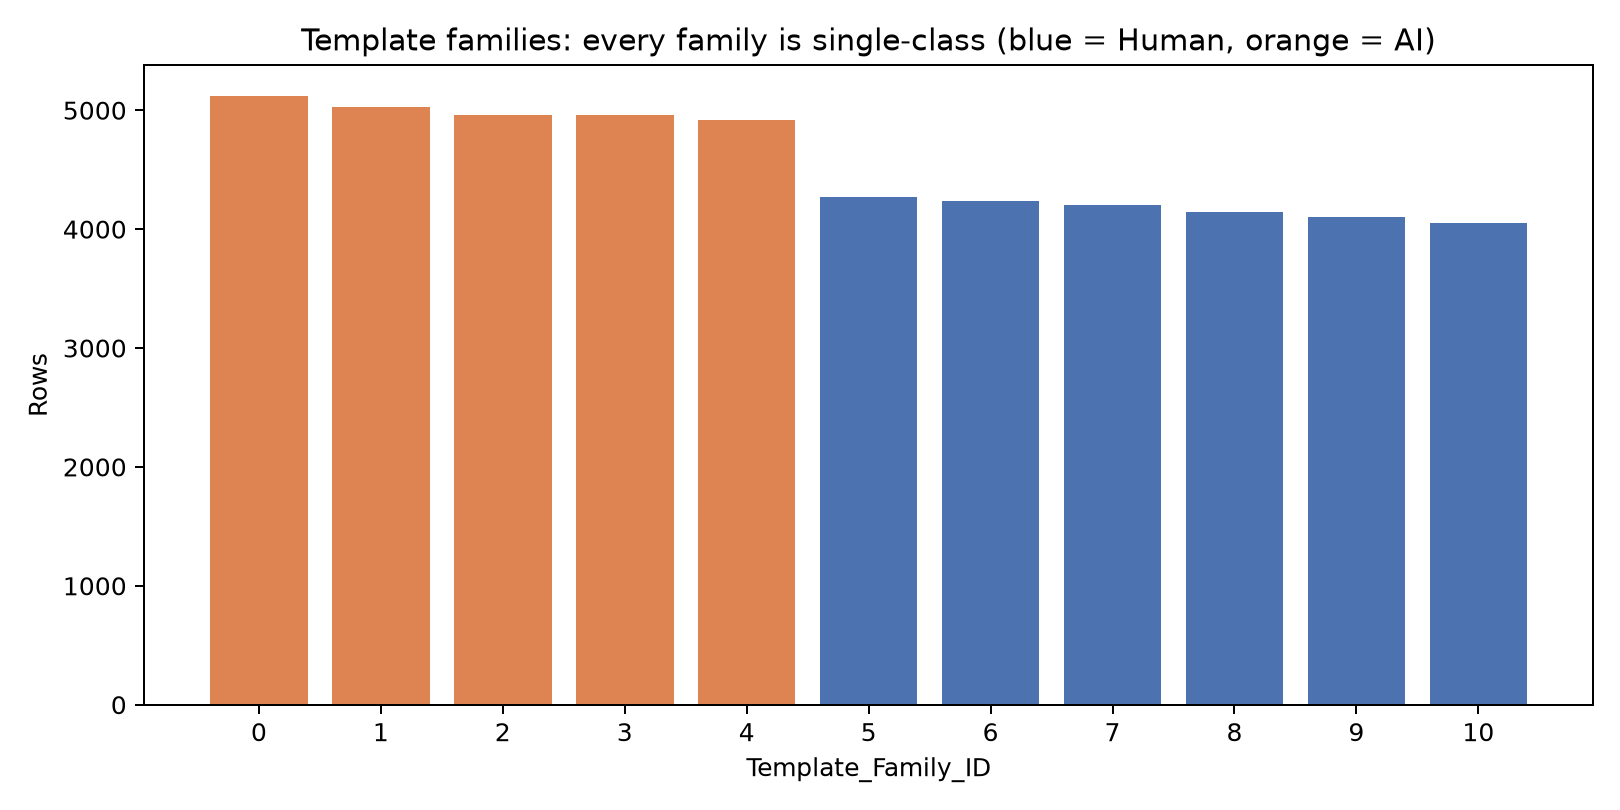

In [8]:
show("template_families_by_class.png", 750)

## Step 4: Train/test split and cross-validation folds

In [9]:
from modeling import SPLITS_PATH

splits = pd.read_csv(SPLITS_PATH)
split_table = splits.groupby("Split").agg(rows=("Label", "size"), ai_share=("Label", "mean"))
split_table["ai_share"] = split_table["ai_share"].round(4)
split_table

,rows,ai_share
Split,,
test,10000,0.5
train,40000,0.5


In [10]:
train_rows = splits[splits["Split"] == "train"]
fold_table = train_rows.groupby("CV_Fold").agg(rows=("Label", "size"), ai_share=("Label", "mean")).round(4)
fold_table

,rows,ai_share
CV_Fold,,
0,8000,0.5
1,8000,0.5
2,8000,0.5
3,8000,0.5
4,8000,0.5


In [11]:
# Leakage check: no near-duplicate group appears in both partitions.
groups_per_split = splits.groupby("NearDup_Group_ID")["Split"].nunique()
print("Near-duplicate groups crossing train/test:", int((groups_per_split > 1).sum()))

Near-duplicate groups crossing train/test: 0


- **80/20 split**, stratified by label and grouped by near-duplicate group, with seed 478.
- **5 cross-validation folds** inside the training set, built the same way. Every model is
  tuned on these same folds.
- The test set is used **once per model**, after tuning is finished.